In [1]:
!pip install transformers datasets accelerate torch -q

In [2]:
!pip install tensorflow

In [3]:
!pip install openpyxl

In [4]:
###IMPORTS NECESSAIRES####
import pandas as pd
import numpy as np
import sklearn
from sklearn import model_selection
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
#from tensorflow.keras import TextVectorization
from tensorflow.keras.layers import Embedding
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional
#from tensforflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
from transformers import CamembertTokenizer
from sklearn.metrics import accuracy_score, precision_score,recall_score, f1_score
from sklearn.metrics import confusion_matrix
#import seaborn as sns
#import spacy
import torch
#sns.set_theme(style="darkgrid")
from sklearn.model_selection import train_test_split
from transformers import CamembertForSequenceClassification
from transformers import TrainingArguments, Trainer

In [5]:
data=pd.read_excel("df_reddit_news.xlsx",engine="openpyxl")
print('Les données ont été chargées avec succès')
print(f'Taille du jeu de données : {len(data)}')

Les données ont été chargées avec succès
Taille du jeu de données : 5251


Melanger les données afin de les diviser en séquences d'entrainement et de validation et test



In [6]:
data=data.sample(frac=1,random_state=42,ignore_index=True)

Division des données en données d'entrainement, de validation et de test

In [7]:
train_df,temp_df = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    stratify=data["annotation"]
)

In [8]:
print(f"Taille des données d'entrainement: {len(train_df)}")

Taille des données d'entrainement: 4200


In [9]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["annotation"]
)

In [10]:
print(f"Taille des données de validation: {len(val_df)}")
print(f"Taille des données de test: {len(test_df)}")

Taille des données de validation: 525
Taille des données de test: 526


In [11]:
train_texts = train_df["text"].astype(str).tolist()
val_texts = val_df["text"].astype(str).tolist()
test_texts = test_df["text"].astype(str).tolist()

train_labels = train_df["annotation"].values
val_labels = val_df["annotation"].values
test_labels = test_df["annotation"].values

Charger le tokeniseur

In [12]:
tokenizer=CamembertTokenizer.from_pretrained("camembert-base")

print("Import du tokeniseur réussi")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

Import du tokeniseur réussi


Chargement des encodings pour l'entrainement, la validation et le test

In [13]:
train_encodings=tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=128)

In [14]:
val_encodings=tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=128)

In [15]:
test_encodings=tokenizer(
    test_texts,
    truncation=True,
    padding=True,
    max_length=128
)

Obtenir les datasets

In [16]:
class Dataset(torch.utils.data.Dataset):

    def __init__(self,encodings,labels):
        self.encodings=encodings
        self.labels=labels

    def __getitem__(self,idx):
        item=dict()

        for key in self.encodings.keys():
            item[key]=torch.tensor(self.encodings[key][idx])

        item["labels"]=torch.tensor(int(self.labels[idx]))

        return item

    def __len__(self):
        return len(self.labels)

Les datasets des données d'entrainement, de validation et de test

In [17]:
train_dataset=Dataset(train_encodings,train_labels)
val_dataset=Dataset(val_encodings,val_labels)
test_dataset=Dataset(test_encodings,test_labels)

print('Datsets entrainement, validation et test créés')

Datsets entrainement, validation et test créés


Charger le modèle

In [18]:
model=CamembertForSequenceClassification.from_pretrained(
    "camembert-base",num_labels=2)

print('Chargement du modèle réussi')

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Chargement du modèle réussi


Les training args

In [19]:
training_args=TrainingArguments(
    output_dir="./results_camembert",
    eval_strategy="epoch",
    save_strategy="epoch",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    load_best_model_at_end=True
)

print("Chargement des training args réussi")

Chargement des training args réussi


In [20]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

Compute metrics

In [21]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [22]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

In [23]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.254641,0.881905,0.966667,0.756522,0.848780
2,0.315337,0.277393,0.883810,0.951872,0.773913,0.853717
3,0.315337,0.339695,0.893333,0.865546,0.895652,0.880342


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=789, training_loss=0.25586341210040153, metrics={'train_runtime': 346.4721, 'train_samples_per_second': 36.367, 'train_steps_per_second': 2.277, 'total_flos': 828799824384000.0, 'train_loss': 0.25586341210040153, 'epoch': 3.0})

In [24]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.315337,0.254641,3,0.881905,0.966667,0.756522,0.848780


{'eval_loss': 0.25464099645614624,
 'eval_accuracy': 0.8819047619047619,
 'eval_precision': 0.9666666666666667,
 'eval_recall': 0.7565217391304347,
 'eval_f1': 0.848780487804878}

In [25]:
predictions=trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)

print(classification_report(test_labels,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.97      0.90       295
           1       0.95      0.77      0.85       231

    accuracy                           0.88       526
   macro avg       0.90      0.87      0.87       526
weighted avg       0.89      0.88      0.88       526



In [26]:
results=pd.DataFrame({
    "texte": test_texts,
    "prediction": y_pred,
    "true label": test_labels
})

results.to_csv("results_camembert_test_20.csv")

In [27]:
new_data = [
    "Quelle belle idée d'augmenter les impôts",
    "Les États-Unis ont de nouveau attaqué la Chine",
    "Super produit, déjà abimé au bout de 3 jours. Je recommande !"
]

print(torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
model.eval()

inputs = tokenizer(
    new_data,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=128
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

pred = torch.argmax(outputs.logits, dim=1)

for phrase, prediction in zip(new_data, pred):
    print("\nPhrase :", phrase)

    if prediction.item() == 1:
        print("Prédiction : sarcastique")
    else:
        print("Prédiction : non sarcastique")

True

Phrase : Quelle belle idée d'augmenter les impôts
Prédiction : sarcastique

Phrase : Les États-Unis ont de nouveau attaqué la Chine
Prédiction : non sarcastique

Phrase : Super produit, déjà abimé au bout de 3 jours. Je recommande !
Prédiction : sarcastique


In [28]:
model.save_pretrained("./classifieur_sarcasme")
tokenizer.save_pretrained("./classifieur_sarcasme")

print("Modèle sauvegardé")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé


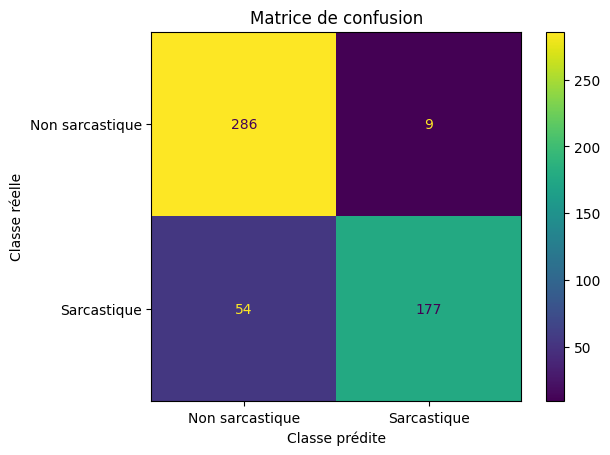

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcul de la matrice de confusion
cm = confusion_matrix(test_labels, y_pred)

# Affichage
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non sarcastique", "Sarcastique"]
)

disp.plot(values_format="d")

plt.title("Matrice de confusion")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()